<a href="https://colab.research.google.com/github/Bilal-data/telco-customer-churn-prediction/blob/main/telco_churn_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
!wget -q -O telco.csv "https://raw.githubusercontent.com/easonlai/telco_customer_churn/main/data/WA_Fn-UseC_-Telco-Customer-Churn_R2.csv"
import pandas as pd
df = pd.read_csv("telco.csv")
print(df.shape)

(7011, 21)


In [15]:
print(df.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'Tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [16]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,Tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,0,0,1,0,1,0,0,1,0,...,0,0,0,0,0,1,2,29.85,29.85,0
1,5575-GNVDE,1,0,0,0,34,1,0,1,1,...,1,0,0,0,1,0,3,56.95,1889.50,0
2,3668-QPYBK,1,0,0,0,2,1,0,1,1,...,0,0,0,0,0,1,3,53.85,108.15,1
3,7795-CFOCW,1,0,0,0,45,0,0,1,1,...,1,1,0,0,1,0,0,42.30,1840.75,0
4,9237-HQITU,0,0,0,0,2,1,0,2,0,...,0,0,0,0,0,1,2,70.70,151.65,1


In [17]:
print(df["Churn"].value_counts())
print(round(df["Churn"].mean() * 100, 1))

Churn
0    5147
1    1864
Name: count, dtype: int64
26.6


In [18]:
print(df.groupby("Churn")["Tenure"].mean())

Churn
0    37.658830
1    17.979077
Name: Tenure, dtype: float64


In [19]:
print(df.groupby("Contract")["Churn"].mean())

Contract
0    0.427499
1    0.112474
2    0.028537
Name: Churn, dtype: float64


In [20]:
print(df.groupby("Churn")["MonthlyCharges"].mean())

Churn
0    61.302856
1    74.451448
Name: MonthlyCharges, dtype: float64


In [21]:
print(df.isna().sum().sum())
print(df.dtypes.value_counts())

0
int64      18
float64     2
object      1
Name: count, dtype: int64


In [22]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(5608, 19) (1403, 19)


In [23]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

accuracy = model.score(X_test, y_test)
print(round(accuracy * 100, 1))

80.3


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [24]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model2 = LogisticRegression(max_iter=1000)
model2.fit(X_train_scaled, y_train)

accuracy2 = model2.score(X_test_scaled, y_test)
print(round(accuracy2 * 100, 1))

80.4


In [25]:
import pandas as pd
coef = pd.Series(model2.coef_[0], index=X.columns).sort_values()
print(coef.tail(5))
print(coef.head(5))

PaperlessBilling    0.159731
StreamingMovies     0.276000
StreamingTV         0.298513
TotalCharges        0.671858
InternetService     0.881691
dtype: float64
Tenure           -1.430386
Contract         -0.616952
MonthlyCharges   -0.375215
OnlineSecurity   -0.315144
TechSupport      -0.274185
dtype: float64


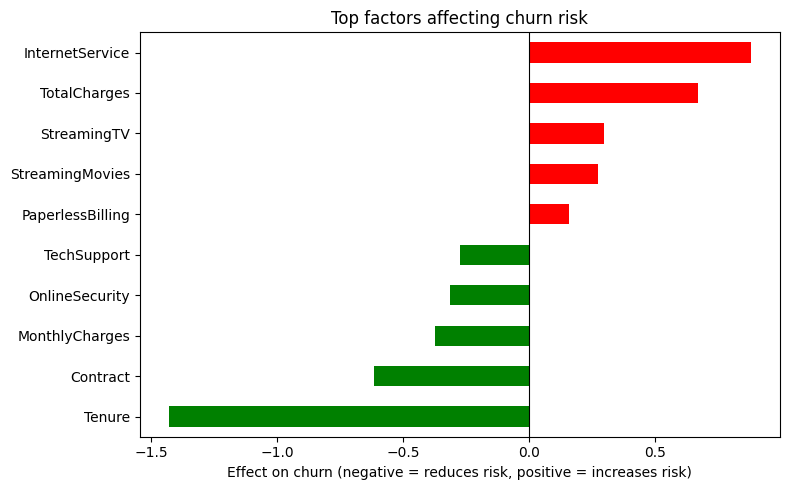

In [26]:
import matplotlib.pyplot as plt

top_features = pd.concat([coef.head(5), coef.tail(5)]).sort_values()
colors = ["green" if v < 0 else "red" for v in top_features]

plt.figure(figsize=(8, 5))
top_features.plot(kind="barh", color=colors)
plt.title("Top factors affecting churn risk")
plt.xlabel("Effect on churn (negative = reduces risk, positive = increases risk)")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

# Telco Customer Churn Prediction

Analyzing a telecom company's customer data (7,011 customers) to understand and predict churn (customers leaving the service).

## Key findings
- Overall churn rate: 26.6%
- Customers who churn have much shorter tenure on average (18 months vs 38 months for those who stay)
- Month-to-month contracts have by far the highest churn rate (42.7%) vs one-year (11.2%) and two-year contracts (2.9%)
- Customers who churn pay higher monthly charges on average (74.5 vs 61.3)

## Predictive model
Built a Logistic Regression model to predict churn using 19 customer features.
- Test accuracy: 80.4% (on 1,403 customers never seen during training)
- Strongest factors reducing churn risk: longer tenure, longer contract commitment
- Strongest factors increasing churn risk: internet service type, total charges, streaming add-ons

## Limitations
- This is a single logistic regression model with default settings; accuracy could likely improve with other models or tuning.
- Dataset is a public sample, not necessarily representative of all telecom markets.